## Monte Carlo and Bootstrap applied to Market Risk Management

#### 0. Libraries and data

In [10]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import datetime as dt


In [11]:
# Download data
def get_data(stocks, start, end):
    prices = yf.download(
        stocks, start=start, end=end, auto_adjust=True
    )["Close"]

    if isinstance(prices, pd.Series):
        prices = prices.to_frame()

    returns = np.log(prices / prices.shift(1)).dropna()
    mean_returns = returns.mean().to_numpy()
    cov_matrix = returns.cov().to_numpy()

    return mean_returns, cov_matrix

#### 1. Portfolio construction

In [ ]:
# All Weather Portfolio by Ray Dalio
stock_list = ["VTI", "TLT", "IEF", "GLD", "DBC"]

end_date = dt.datetime.now()
start_date = end_date - dt.timedelta(days=300)

mean_returns, cov_matrix = get_data(
    stock_list, start_date, end_date
)

# Portfolio weights
weights = np.array([0.30, 0.40, 0.15, 0.075, 0.075])

# Verify allocation equals 100%
assert np.isclose(weights.sum(), 1.0), "Portfolio weights must sum to 1.0"

print("Assets:", stock_list)
print("Weights:", weights)

initial_portfolio = 10000
T = 100 # Number of simulated time steps (100 days)

rng = np.random.default_rng(42) # Random Number Generator (Like np.random seed)

# Cholesky decomposition for correlated asset returns
L = np.linalg.cholesky(cov_matrix)

[*********************100%***********************]  5 of 5 completed

Assets: ['VTI', 'TLT', 'IEF', 'GLD', 'DBC']
Weights: [0.3   0.4   0.15  0.075 0.075]


#### 2. Monte Carlo simulation

In [13]:
# Monte Carlo simulation
def simulate_portfolios(n_sims, rng):
    # Generate correlated multivariate normal log returns
    Z = rng.standard_normal((n_sims, T, len(weights)))

    # Shape: simulations x days x assets
    log_returns = (Z @ L.T) + mean_returns
    # Convert log returns to simple returns
    simple_returns = np.exp(log_returns) - 1

    # Daily portfolio returns (daily rebalancing assumption)
    portfolio_returns = simple_returns @ weights

    # Simulated portfolio values
    portfolio_values = initial_portfolio * np.cumprod(
        1 + portfolio_returns, axis=1
    )

    return portfolio_values

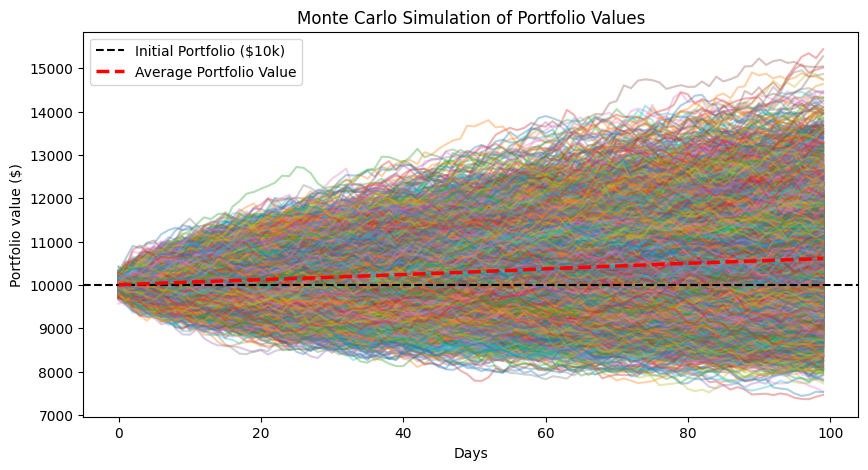

In [14]:
# Main simulation
mc_sims = 10000
portfolio_sims = simulate_portfolios(mc_sims, rng)
mean_portfolio_path = portfolio_sims.mean(axis=0)

plt.figure(figsize=(10, 5))
plt.plot(portfolio_sims[:10000].T, alpha=0.35)
plt.axhline(initial_portfolio,color='black', linestyle="--",label="Initial Portfolio ($10k)")
plt.plot(mean_portfolio_path,color="red",linestyle="--",linewidth=2.5,label="Average Portfolio Value",)
plt.xlabel("Days")
plt.ylabel("Portfolio value ($)")
plt.title("Monte Carlo Simulation of Portfolio Values")
plt.legend(loc="upper left")
plt.show()

#### 3. Value at Risk (VaR) and Expected Shortfall (ES)

In [15]:
# Value at Risk (VaR) and Expected Shortfall (ES)

def estimate_risk(portfolio_values, alpha=5):
    # Loss is positive when the portfolio loses value
    losses = initial_portfolio - portfolio_values[:, -1]

    # 95% VaR corresponds to the 95th percentile of losses
    var = np.percentile(losses, 100 - alpha)

    # Average loss in the worst alpha% of outcomes
    es = losses[losses >= var].mean()

    return var, es, losses


var, es, losses = estimate_risk(portfolio_sims)

print(f"95% VaR: ${var:,.2f}")
print(f"95% Expected Shortfall: ${es:,.2f}")

95% VaR: $1,048.52
95% Expected Shortfall: $1,398.00


#### 4. Monte Carlo estimator accuracy: standard error, MSE and approximate unbiasedness


VaR estimator
Reference estimate: $1,032.26
Average batch estimate: $1,019.10
Estimated bias: $-13.16
Standard error (one batch): $55.52
MSE (one batch): 3,224.36

ES estimator
Reference estimate: $1,388.05
Average batch estimate: $1,374.91
Estimated bias: $-13.14
Standard error (one batch): $63.50
MSE (one batch): 4,164.47

VaR estimation accuracy
 Simulations per batch  Mean VaR  Standard error      MSE
                   100    977.76          198.29 41503.47
                   250   1004.27          116.63 14113.83
                   500   1006.72           68.54  5256.21
                  1000   1010.05           58.49  3846.10


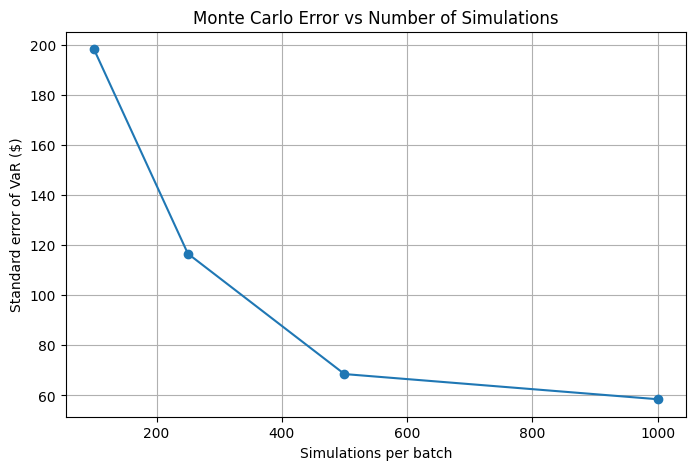

In [16]:
# A large simulation is used as an approximate benchmark.
# It is NOT the exact theoretical VaR or ES.

# Benchmark
reference_rng = np.random.default_rng(123)
reference_sims = simulate_portfolios(100000, reference_rng)

reference_var, reference_es, _ = estimate_risk(reference_sims)

# Estimate VaR and ES independently across batches
n_batches = 100
batch_size = 1000

batch_vars = []
batch_ess = []

batch_rng = np.random.default_rng(456)

for _ in range(n_batches):
    batch_sims = simulate_portfolios(batch_size, batch_rng)
    batch_var, batch_es, _ = estimate_risk(batch_sims)

    batch_vars.append(batch_var)
    batch_ess.append(batch_es)

batch_vars = np.array(batch_vars)
batch_ess = np.array(batch_ess)


def evaluate_estimator(estimates, reference, label):
    # Average estimate across independent batches
    average_estimate = estimates.mean()

    # Bias relative to the approximate reference
    bias = average_estimate - reference

    # Empirical standard error of one batch estimate
    standard_error = estimates.std(ddof=1)

    # MSE relative to the approximate reference
    mse = np.mean((estimates - reference) ** 2)

    print(f"\n{label}")
    print(f"Reference estimate: ${reference:,.2f}")
    print(f"Average batch estimate: ${average_estimate:,.2f}")
    print(f"Estimated bias: ${bias:,.2f}")
    print(f"Standard error (one batch): ${standard_error:,.2f}")
    print(f"MSE (one batch): {mse:,.2f}")


evaluate_estimator(batch_vars, reference_var, "VaR estimator")
evaluate_estimator(batch_ess, reference_es, "ES estimator")


# How accuracy changes as simulations increase
batch_counts = [100, 250, 500, 1_000]
accuracy_results = []

for size in batch_counts:
    # Use fresh batches for each sample size
    estimates = []

    for _ in range(50):
        sims = simulate_portfolios(size, batch_rng)
        batch_var, _, _ = estimate_risk(sims)
        estimates.append(batch_var)

    estimates = np.array(estimates)

    accuracy_results.append({
        "Simulations per batch": size,
        "Mean VaR": estimates.mean(),
        "Standard error": estimates.std(ddof=1),
        "MSE": np.mean((estimates - reference_var) ** 2)
    })

accuracy_df = pd.DataFrame(accuracy_results)
print("\nVaR estimation accuracy")
print(accuracy_df.round(2).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(accuracy_df["Simulations per batch"],accuracy_df["Standard error"],marker="o")
plt.xlabel("Simulations per batch")
plt.ylabel("Standard error of VaR ($)")
plt.title("Monte Carlo Error vs Number of Simulations")
plt.grid(True)
plt.show()

#### 5. Bootstrap: uncertainty in rare-event probability (10%)

In [17]:
# Define a severe loss as losing at least 10%
# of the initial portfolio value
loss_threshold = 0.10 * initial_portfolio

# Indicator: 1 if severe loss, 0 otherwise
severe_loss = (losses >= loss_threshold).astype(int)

# Original estimated probability
p_hat = severe_loss.mean()

# Bootstrap settings
n_bootstrap = 5000
rng_boot = np.random.default_rng(123)

bootstrap_probabilities = np.empty(n_bootstrap)
n = len(severe_loss)

# Resample observations WITH replacement
for b in range(n_bootstrap):
    bootstrap_sample = rng_boot.choice(severe_loss,size=n,replace=True)
    bootstrap_probabilities[b] = bootstrap_sample.mean()

# Bootstrap standard error
bootstrap_se = bootstrap_probabilities.std(ddof=1)

# Percentile 95% bootstrap confidence interval
ci_lower, ci_upper = np.percentile(bootstrap_probabilities, [2.5, 97.5])

print("\nBootstrap analysis of severe-loss probability")
print(f"Severe-loss threshold: ${loss_threshold:,.2f}")
print(f"Original estimated probability: {p_hat:.4%}")
print(f"Bootstrap standard error: {bootstrap_se:.4%}")
print(f"95% bootstrap confidence interval: "f"[{ci_lower:.4%}, {ci_upper:.4%}]")


Bootstrap analysis of severe-loss probability
Severe-loss threshold: $1,000.00
Original estimated probability: 5.6400%
Bootstrap standard error: 0.2308%
95% bootstrap confidence interval: [5.2100%, 6.1000%]


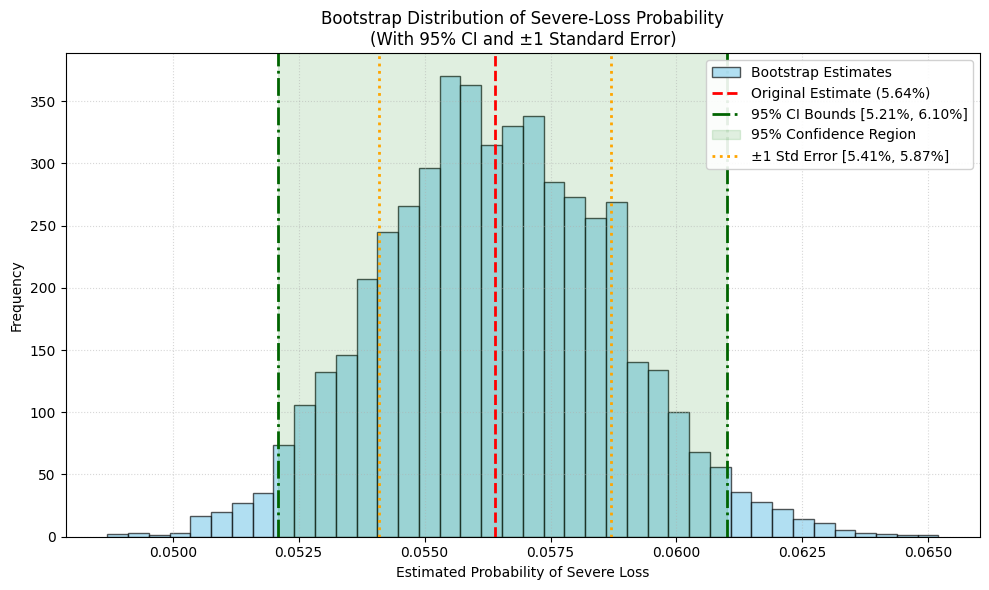

In [18]:
# Plotting the Bootstrap Distribution with CI and SE
plt.figure(figsize=(10, 6))

# 1. Main Histogram
plt.hist(bootstrap_probabilities,bins=40,edgecolor="black",alpha=0.65,color="skyblue",label="Bootstrap Estimates",)

# 2. Original Estimate Line
plt.axvline(p_hat,color="red",linestyle="--",linewidth=2,label=f"Original Estimate ({p_hat:.2%})",)

# 3. 95% Confidence Interval Lines & Shading
plt.axvline(ci_lower,color="darkgreen",linestyle="-.", linewidth=2, label=f"95% CI Bounds [{ci_lower:.2%}, {ci_upper:.2%}]",)
plt.axvline(ci_upper, color="darkgreen", linestyle="-.", linewidth=2)

plt.axvspan(ci_lower,ci_upper,color="green",alpha=0.12,label="95% Confidence Region",)

# 4. Standard Error Bounds (+/- 1 SE around mean)
se_lower = p_hat - bootstrap_se
se_upper = p_hat + bootstrap_se

plt.axvline(se_lower,color="orange",linestyle=":", linewidth=2,label=f"±1 Std Error [{se_lower:.2%}, {se_upper:.2%}]",)
plt.axvline(se_upper, color="orange", linestyle=":", linewidth=2)

# Labels & Formatting
plt.xlabel("Estimated Probability of Severe Loss")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of Severe-Loss Probability\n(With 95% CI and ±1 Standard Error)")
plt.legend(loc="upper right", framealpha=0.9)
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()